# Reproducible tables and figures
**Point-of-care HPV testing: a dream or reality? A systematic review of diagnostic performance and implementation challenges** (Martins et al.), *Journal of Medical Screening*.

This notebook regenerates every table (LaTeX fragments `tables/tab*.tex`) and every figure (`figures/*.pdf|png|tiff`) of the manuscript from the CSV files in `data/`. No number is typed inside the code; all values come from the CSVs, which were transcribed from the manuscript tables and text.

**How to run:** open in Jupyter with the R kernel (`IRkernel`), run *Kernel → Restart & Run All*. Working directory = folder containing `data/`. Required packages: ggplot2, dplyr, tidyr, readr, stringr, patchwork, ragg, systemfonts.

**Data caveats (see the pending-items report):** point estimates of Einstein 2014 (~94 / ~92) are approximations and Lin 2025 sensitivity (>90) is a lower bound; both are flagged in the Fig. 3 symbols. Table 1 has no data in the source document, so its CSV is a template.

## 0. Setup

In [1]:
# ---- Packages -------------------------------------------------------------
suppressPackageStartupMessages({
  library(ggplot2)   # figures
  library(dplyr)     # data handling
  library(tidyr)
  library(readr)     # CSV input
  library(stringr)
  library(patchwork) # multi-panel figures
})

# ---- Paths (relative to the folder that contains this notebook) -------------
DATA <- "data"; FIG <- "figures"; TAB <- "tables"
for (d in c(FIG, TAB)) dir.create(d, showWarnings = FALSE, recursive = TRUE)

# ---- Font: Arial/Helvetica metrics if installed, otherwise a close substitute ---
pick_font <- function(candidates = c("Arial", "Helvetica", "Liberation Sans", "DejaVu Sans")) {
  have <- unique(systemfonts::system_fonts()$family)
  hit  <- candidates[candidates %in% have]
  if (length(hit)) hit[1] else "sans"
}
FONT <- pick_font()

# ---- Colour-blind-safe palette (Okabe & Ito 2008) -----------------------------
OI <- c(blue = "#0072B2", vermillion = "#D55E00", green = "#009E73",
        orange = "#E69F00", sky = "#56B4E9", grey = "#B8B8B8")

# ---- Palettes chosen so that adjacent classes also differ in lightness (L*), i.e. they survive greyscale
# printing; hues remain colour-blind-safe (Okabe-Ito family). Checked numerically in section 6.
PAL_GROUP <- c("Commercial platforms" = "#0B4A7D", "CRISPR-Cas" = "#C24A00", "Isothermal amplification and mRNA" = "#25A57C",
               "Self-sampling" = "#F2B01E", "Other POC, reviews and context" = "#DEDEDE")
PAL_CLASS <- c("1" = "#A9CCE3", "2" = "#6FA8D0", "10" = "#2A6FA8", "15" = "#08306B")   # sequential, studies per country
PAL_NONE  <- "#F0F0F0"                                                              # countries without an included study
PAL_ROC   <- c("Commercial platforms" = "#0B4A7D", "Emerging platforms" = "#E69F00")
PAL_BIAS  <- c(Low = "#0B4A7D", Moderate = "#F2B01E", High = "#C24A00")

# ---- Common theme: plain, thin axes, no box, small type (journal figures) ----
theme_jms <- function(base = 8) {
  theme_classic(base_size = base, base_family = FONT) +
    theme(axis.line        = element_line(linewidth = 0.4, colour = "grey15"),
          axis.ticks       = element_line(linewidth = 0.4, colour = "grey15"),
          axis.text        = element_text(colour = "grey15", size = base - 0.5),
          axis.title       = element_text(colour = "grey10", size = base),
          legend.background = element_blank(),
          legend.key        = element_blank(),
          legend.title      = element_text(face = "bold", size = base - 0.5),
          legend.text       = element_text(size = base - 1),
          plot.tag          = element_text(face = "bold", size = base + 3),
          plot.margin       = margin(4, 6, 4, 4))
}

# ---- Save every figure as vector PDF + 600-dpi PNG and TIFF (journal requires >= 300 dpi)
save_fig <- function(p, name, width_mm, height_mm) {
  ggsave(file.path(FIG, paste0(name, ".pdf")),  p, width = width_mm, height = height_mm,
         units = "mm", device = cairo_pdf)
  ggsave(file.path(FIG, paste0(name, ".png")),  p, width = width_mm, height = height_mm,
         units = "mm", dpi = 600, device = ragg::agg_png)
  ggsave(file.path(FIG, paste0(name, ".tiff")), p, width = width_mm, height = height_mm,
         units = "mm", dpi = 600, device = ragg::agg_tiff, compression = "lzw")
  invisible(p)
}
# ---- Show a figure inside the notebook at its real aspect ratio
show_fig <- function(p, width_mm, height_mm) {
  options(repr.plot.width = width_mm / 25.4, repr.plot.height = height_mm / 25.4, repr.plot.res = 130)
  print(p)
}
cat("Font used:", FONT, "| R", as.character(getRversion()), "| ggplot2", as.character(packageVersion("ggplot2")), "\n")


Font used: Liberation Sans | R 4.3.3 | ggplot2 3.4.4 


## 1. Tables
Table 1 (platform specifications, from manufacturer documents and WHO prequalification reports) and Table 2 (accuracy ranges) are in the main text. The PICOS criteria (Supplemental Appendix 3) and the 49 included studies (Supplemental Appendix 4, landscape longtable) are in the Supplemental Material.

In [2]:
# ---- LaTeX escaping used for every table cell ---------------------------------
tex_escape <- function(x) {
  x <- as.character(x); x[is.na(x)] <- ""
  fixed <- c("&" = "\\&", "%" = "\\%", "_" = "\\_", "#" = "\\#",
             "≥" = "$\\geq$", "≤" = "$\\leq$", "μ" = "$\\mu$", "κ" = "$\\kappa$",
             "–" = "--", "é" = "\\'e", "ó" = "\\'o", "í" = "\\'i", "á" = "\\'a",
             "ã" = "\\~a", "ç" = "\\c{c}")
  for (k in names(fixed)) x <- gsub(k, fixed[[k]], x, fixed = TRUE)
  x <- gsub("~(?=[0-9])", "$\\\\sim$", x, perl = TRUE)                       # ~94  -> $\sim$94
  x <- gsub("(?<![A-Za-z0-9$\\\\])>(?=\\s?[0-9])", "$>$", x, perl = TRUE)    # >90  -> $>$90
  x <- gsub("(?<=[0-9])-(?=[0-9])", "--", x, perl = TRUE)                    # 71-90 -> 71--90
  x
}
write_tex <- function(lines, file) writeLines(lines, file.path(TAB, file), useBytes = TRUE)

# ======================= Table 1: platform specifications (sources in the CSV cite keys; body was missing in the source .docx) ===
t1 <- read_csv(file.path(DATA, "table1_platforms.csv"), col_types = cols(.default = "c"), show_col_types = FALSE)
stopifnot(nrow(t1) > 0, identical(names(t1), c("characteristic", "careHPV", "Xpert HPV")))
# Table 1 cells already contain LaTeX (\\cite, \\textdegree, $\\times$): only % is escaped here
esc1 <- function(x) gsub("%", "\\%", x, fixed = TRUE)
write_tex(c("\\begin{tabular}{@{}>{\\raggedright\\arraybackslash}p{28mm}p{66mm}p{66mm}@{}}", "\\toprule",
            "\\textbf{Characteristic} & \\textbf{careHPV (QIAGEN)} & \\textbf{Xpert HPV (Cepheid)} \\\\", "\\midrule",
            apply(as.matrix(t1), 1, function(r) paste0("\\textbf{", r[1], "} & ", esc1(r[2]), " & ", esc1(r[3]), " \\\\")),
            "\\bottomrule", "\\end{tabular}"), "tab1.tex")

# ======================= Table 2 (main text): accuracy ranges by platform ==========================
t4 <- read_csv(file.path(DATA, "table4_accuracy.csv"), col_types = cols(.default = "c"), show_col_types = FALSE)
write_tex(c("\\begin{tabular}{@{}p{30mm}p{20mm}p{24mm}p{24mm}p{44mm}@{}}", "\\toprule",
            "\\textbf{Platform} & \\textbf{Studies (n)} & \\textbf{Sensitivity (range)} & \\textbf{Specificity (range)} & \\textbf{Studies with largest N} \\\\",
            "\\midrule",
            apply(t4, 1, function(r) paste0(paste(tex_escape(r), collapse = " & "), " \\\\")),
            "\\bottomrule", "\\end{tabular}"), "tab2.tex")
# Single-column version (84 mm) used in the article so the table sits in the text column
write_tex(c("\\scriptsize\\sf\\setlength{\\tabcolsep}{1.5pt}",
            "\\begin{tabular}{@{}p{14mm}p{12mm}p{17mm}p{16mm}p{19mm}@{}}", "\\toprule",
            "\\textbf{Platform} & \\textbf{Studies (n)} & \\textbf{Sensitivity (range)} & \\textbf{Specificity (range)} & \\textbf{Largest N study} \\\\",
            "\\midrule",
            apply(t4, 1, function(r) paste0(paste(tex_escape(r), collapse = " & "), " \\\\")),
            "\\bottomrule", "\\end{tabular}"), "tab2_col.tex")

# ======================= Supplemental Appendix 3: PICOS =============================================
t2 <- read_csv(file.path(DATA, "table2_picos.csv"), col_types = cols(.default = "c"), show_col_types = FALSE)
write_tex(c("\\begin{longtable}{@{}p{26mm}p{94mm}@{}}", "\\toprule",
            "\\textbf{Element} & \\textbf{Description} \\\\", "\\midrule", "\\endfirsthead", "\\toprule", "\\textbf{Element} & \\textbf{Description} \\\\", "\\midrule", "\\endhead",
            paste0("\\textbf{", tex_escape(t2$element), "} \\textbf{(", t2$letter, ")} & ", tex_escape(t2$description), " \\\\"),
            "\\bottomrule", "\\end{longtable}"), "tabS_picos.tex")

# ======================= Supplemental Appendix 4: the 49 included studies (landscape longtable) =========
t3 <- read_csv(file.path(DATA, "table3_studies.csv"), col_types = cols(.default = "c"), show_col_types = FALSE)
stopifnot(nrow(t3) == 49, !anyDuplicated(t3$id))
cols3 <- c("id", "first_author", "year", "country", "poc_platform", "self_sampling", "n", "sensitivity", "specificity", "gold_standard")
head3 <- "ID & First author & Year & Country & POC platform & Self-samp. & \\hspace{1mm}$N$ & Sens.\\ (\\%) & Spec.\\ (\\%) & Gold standard \\\\"
body3 <- character()
for (ct in unique(t3$category)) {
  s <- t3[t3$category == ct, ]
  body3 <- c(body3, "\\midrule", paste0("\\multicolumn{10}{@{}l}{\\textbf{", tex_escape(ct), "}} \\\\*"),
             apply(s[, cols3], 1, function(r) paste0(paste(tex_escape(r), collapse = " & "), " \\\\")))
}
write_tex(c("\\scriptsize\\sf\\setlength{\\tabcolsep}{2.5pt}\\renewcommand{\\arraystretch}{0.95}",
            "\\begin{tabular}{@{}r p{21mm} l p{18mm} p{33mm} p{10mm} r p{27mm} p{11mm} p{16mm}@{}}",
            "\\toprule", head3, "\\midrule",
            body3[-1], "\\bottomrule", "\\end{tabular}"), "tabS_studies.tex")

# Also export the analysis tables as CSV for supplementary use
write_csv(t3, file.path(TAB, "Table3_included_studies.csv")); write_csv(t4, file.path(TAB, "Table4_accuracy_ranges.csv"))
print(list.files(TAB))
head(t3[, cols3], 8)


 [1] "Table3_included_studies.csv" "Table4_accuracy_ranges.csv" 
 [3] "build_tab2_layout.py"        "split_tab2.py"              
 [5] "tab1.tex"                    "tab2.tex"                   
 [7] "tab2_col.tex"                "tab2_part1.tex"             
 [9] "tab2_part2.tex"              "tab2_part3.tex"             
[11] "tab2_part4.tex"              "tab2_part5.tex"             
[13] "tab2_part6.tex"              "tab2_part7.tex"             
[15] "tabS_picos.tex"              "tabS_studies.tex"           


id,first_author,year,country,poc_platform,self_sampling,n,sensitivity,specificity,gold_standard
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Katanga,2021,Tanzania,careHPV,No,"4,080",90.7,84.2,HC2
2,Clifford,2023,Bhutan,careHPV,Yes,"2,590",75.9,90.6,PCR GP5+/6+
3,Umulisa,2018,Rwanda,careHPV,No,764,71.0,88.0,PCR
4,Hang,2024,Cambodia,careHPV,Yes,375,Agreement 95.7% (κ=0.66),NR,PCR
5,Lorenzi,2016,Brazil,careHPV,No,NR,NR,NR,PCR
6,Wang,2025,China,careHPV,No,NR,NR,NR,PCR
7,Einstein,2014,USA,Xpert HPV,No,NR,~94,~92,HC2
8,Denny,2023,South Africa,Xpert HPV,No,NR,NR,NR,PCR


## 2. Figure 1 — PRISMA 2020 flow diagram
All counts read from `data/prisma_flow.csv`; the code stops if the arithmetic is inconsistent (identified − excluded = sought; assessed − excluded = included).

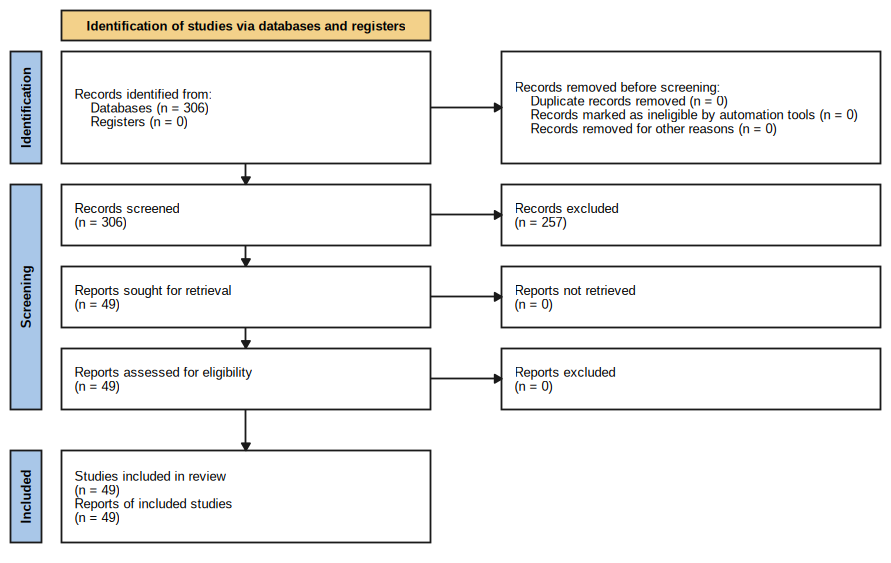

In [3]:
fl <- read_csv(file.path(DATA, "prisma_flow.csv"), show_col_types = FALSE)
n  <- setNames(as.integer(fl$n), fl$item)
# internal consistency: records identified - records excluded = reports sought (306 - 257 = 49)
stopifnot(n[["records_identified_databases"]] - n[["records_excluded"]] == n[["reports_sought"]],
          n[["reports_assessed"]] - n[["reports_excluded"]] == n[["studies_included"]])

bx <- data.frame(
  x0 = c(12, 98, 12, 98, 12, 98, 12, 98, 12), x1 = c(84, 172, 84, 172, 84, 172, 84, 172, 84),
  y0 = c(88, 88, 72, 72, 56, 56, 40, 40, 14), y1 = c(110, 110, 84, 84, 68, 68, 52, 52, 32))
bx$label <- c(
  sprintf("Records identified from:\n    Databases (n = %d)\n    Registers (n = %d)", n[["records_identified_databases"]], n[["records_identified_registers"]]),
  sprintf("Records removed before screening:\n    Duplicate records removed (n = %d)\n    Records marked as ineligible by automation tools (n = %d)\n    Records removed for other reasons (n = %d)",
          n[["duplicates_removed"]], n[["marked_ineligible_automation"]], n[["removed_other_reasons"]]),
  sprintf("Records screened\n(n = %d)", n[["records_screened"]]),
  sprintf("Records excluded\n(n = %d)", n[["records_excluded"]]),
  sprintf("Reports sought for retrieval\n(n = %d)", n[["reports_sought"]]),
  sprintf("Reports not retrieved\n(n = %d)", n[["reports_not_retrieved"]]),
  sprintf("Reports assessed for eligibility\n(n = %d)", n[["reports_assessed"]]),
  sprintf("Reports excluded\n(n = %d)", n[["reports_excluded"]]),
  sprintf("Studies included in review\n(n = %d)\nReports of included studies\n(n = %d)", n[["studies_included"]], n[["reports_included"]]))

side <- data.frame(x0 = 2, x1 = 8, y0 = c(88, 40, 14), y1 = c(110, 84, 32), label = c("Identification", "Screening", "Included"))
arr  <- arrow(length = unit(1.6, "mm"), type = "closed")
vlines <- data.frame(x = 48, y = c(88, 72, 56, 40), yend = c(84, 68, 52, 32))
hlines <- data.frame(y = c(99, 78, 62, 46), x = 84, xend = 98)

p1 <- ggplot() +
  geom_rect(data = data.frame(x0 = 12, x1 = 84, y0 = 112, y1 = 118), aes(xmin = x0, xmax = x1, ymin = y0, ymax = y1),
            fill = "#F3D18A", colour = "grey10", linewidth = 0.35) +
  annotate("text", x = 48, y = 115, label = "Identification of studies via databases and registers",
           family = FONT, fontface = "bold", size = 2.35) +
  geom_rect(data = side, aes(xmin = x0, xmax = x1, ymin = y0, ymax = y1), fill = "#A9C7E8", colour = "grey10", linewidth = 0.35) +
  geom_text(data = side, aes(x = (x0 + x1) / 2, y = (y0 + y1) / 2, label = label), angle = 90,
            family = FONT, fontface = "bold", size = 2.35) +
  geom_rect(data = bx, aes(xmin = x0, xmax = x1, ymin = y0, ymax = y1), fill = "white", colour = "grey10", linewidth = 0.35) +
  geom_text(data = bx, aes(x = x0 + 2.5, y = (y0 + y1) / 2, label = label), hjust = 0, vjust = 0.5,
            family = FONT, size = 2.35, lineheight = 0.95) +
  geom_segment(data = vlines, aes(x = x, xend = x, y = y, yend = yend), arrow = arr, linewidth = 0.35, colour = "grey10") +
  geom_segment(data = hlines, aes(x = x, xend = xend, y = y, yend = y), arrow = arr, linewidth = 0.35, colour = "grey10") +
  coord_fixed(xlim = c(0, 174), ylim = c(10, 120), expand = FALSE) + theme_void()
save_fig(p1, "Figure1_PRISMA_flow", 174, 110); show_fig(p1, 174, 110)


## 3. Figure 2 — Characteristics of the included studies
(a) studies by year and technology group; (b) geographic distribution (Robinson projection; `maps` + `sf`, no download); (c) studies per country. Country = the `country` field of `data/table3_studies.csv`. Two multi-country reviews are not assigned to a country and appear only in panel c.

In [4]:
t3 <- read_csv(file.path(DATA, "table3_studies.csv"), col_types = cols(.default = "c"), show_col_types = FALSE)
grp_levels <- names(PAL_GROUP)
grp_map <- c("Commercial Platforms" = grp_levels[1], "CRISPR-Cas Technologies" = grp_levels[2],
             "Isothermal Amplification (LAMP, RPA, HDA)" = grp_levels[3], "mRNA (approximation to Methylation)" = grp_levels[3],
             "Self-Sampling" = grp_levels[4], "Other POC Technologies" = grp_levels[5], "Reviews and Context (non-primary)" = grp_levels[5])
cnt <- t3 |> mutate(year = as.integer(year), group = factor(unname(grp_map[category]), levels = grp_levels)) |>
  count(year, group)
tot <- cnt |> group_by(year) |> summarise(n = sum(n), .groups = "drop")
stopifnot(sum(tot$n) == 49, !any(is.na(cnt$group)))
recent <- sum(tot$n[tot$year >= 2024]); pct_recent <- round(100 * recent / sum(tot$n))

p2 <- ggplot(cnt, aes(year, n, fill = group)) +
  geom_col(width = 0.72, colour = "grey30", linewidth = 0.2, position = position_stack(reverse = TRUE)) +
  geom_text(data = tot, aes(year, n, label = n), inherit.aes = FALSE, vjust = -0.45, size = 2.5, family = FONT, colour = "grey10") +
  annotate("segment", x = 2023.6, xend = 2026.4, y = 12.9, yend = 12.9, linewidth = 0.4, colour = "grey15") +
  annotate("segment", x = c(2023.6, 2026.4), xend = c(2023.6, 2026.4), y = 12.9, yend = 12.4, linewidth = 0.4, colour = "grey15") +
  annotate("text", x = 2025, y = 13.15, label = sprintf("2024–2026: %d of %d studies (%d%%)", recent, sum(tot$n), pct_recent),
           size = 2.5, family = FONT, vjust = 0, colour = "grey10") +
  scale_fill_manual(values = PAL_GROUP, name = NULL) +
  scale_x_continuous(breaks = 2014:2026, expand = expansion(add = 0.6)) +
  scale_y_continuous(breaks = seq(0, 12, 2), limits = c(0, 14), expand = c(0, 0)) +
  labs(x = "Year of publication", y = "Included studies (n)") +
  guides(fill = guide_legend(nrow = 2, byrow = TRUE)) +
  theme_jms() + theme(legend.position = "top", legend.justification = "left", legend.margin = margin(0, 0, 2, 0), legend.text = element_text(size = 7, margin = margin(l = 2, r = 10)),
                      panel.grid.major.y = element_line(colour = "grey90", linewidth = 0.3))
# (saved as panel a of Figure 2 in the next chunk)


In [5]:
suppressPackageStartupMessages(library(sf))
# ---- Study counts per country, straight from Table 3 (column `country`) ----------------
t3  <- read_csv(file.path(DATA, "table3_studies.csv"), col_types = cols(.default = "c"), show_col_types = FALSE)
reg <- read_csv(file.path(DATA, "country_regions.csv"), show_col_types = FALSE)
disp <- c(USA = "United States", PNG = "Papua New Guinea", Multiple = "Multiple countries (reviews)")
cn <- t3 |> count(country, name = "n") |>
  mutate(label = ifelse(country %in% names(disp), unname(disp[country]), country))
stopifnot(sum(cn$n) == 49, setequal(cn$country, reg$country))     # every country has a region; all 49 studies counted
single <- cn |> filter(country != "Multiple")
cat("Countries with >= 1 study:", nrow(single), "| studies in 'Multiple':", cn$n[cn$country == "Multiple"], "\n")

# ---- Polygons: `maps` world database (bundled with R, no download) -------------------------
w <- st_as_sf(maps::map("world", fill = TRUE, plot = FALSE))
w$country <- sub(":.*$", "", w$ID)                                   # merge islands into their country
w <- w[!grepl("enclave|hole", w$ID) & w$country != "Antarctica", ]    # drop enclaves/lakes and Antarctica
s2_prev <- sf_use_s2(FALSE)                                           # planar lon/lat clipping (robust here)
# Chukotka (Russia) and part of Fiji have longitudes > 180 in this database: split at 180 and shift the
# excess back by 360 so that they are not drawn across the whole map after projection.
box_in  <- st_as_sfc(st_bbox(c(xmin = -180, xmax = 180, ymin = -90, ymax = 90), crs = st_crs(w)))
box_out <- st_as_sfc(st_bbox(c(xmin =  180, xmax = 200, ymin = -90, ymax = 90), crs = st_crs(w)))
geom <- st_geometry(w)
for (i in which(sapply(geom, function(g) st_bbox(g)[["xmax"]] > 180))) {
  g <- st_make_valid(geom[i]); a <- st_intersection(g, box_in); b <- st_intersection(g, box_out)
  geom[i] <- st_union(c(a, st_set_crs(b - c(360, 0), st_crs(w))))
}
st_geometry(w) <- geom
w  <- st_make_valid(w)
wp <- st_make_valid(st_transform(w, "+proj=robin +lon_0=0 +datum=WGS84"))   # Robinson projection
wc <- suppressWarnings(wp |> group_by(country) |> summarise(.groups = "drop") |> st_make_valid())
to_map <- c(USA = "USA", PNG = "Papua New Guinea")                 # Table 3 label -> `maps` name
single$map_name <- ifelse(single$country %in% names(to_map), unname(to_map[single$country]), single$country)
stopifnot(all(single$map_name %in% wc$country))                    # every study country has a polygon
lv <- as.character(sort(unique(single$n)))                         # exact counts used as classes: 1, 2, 10, 15
wc <- wc |> left_join(select(single, map_name, n), by = c("country" = "map_name")) |>
  mutate(cls = factor(n, levels = as.integer(lv), labels = lv))
pal <- PAL_CLASS[lv]

# ---- Markers for small countries (area < 500,000 km2) so that they remain visible --------
area_m2 <- as.numeric(st_area(wc))                                  # projected area (Robinson), m2
sm  <- wc[!is.na(wc$n) & area_m2 < 5e11, ]
ctr <- do.call(rbind, lapply(seq_len(nrow(sm)), function(i) {
  p <- st_cast(st_geometry(sm)[i], "POLYGON"); st_coordinates(st_point_on_surface(p[which.max(as.numeric(st_area(p)))]))[1, 1:2] }))
mk <- data.frame(x = ctr[, 1], y = ctr[, 2], cls = sm$cls)

pm <- ggplot() +
  geom_sf(data = wc, aes(fill = cls), colour = "grey55", linewidth = 0.1) +
  geom_point(data = mk, aes(x, y, fill = cls), shape = 21, colour = "grey10", size = 1.4, stroke = 0.35, show.legend = FALSE) +
  scale_fill_manual(values = pal, na.value = PAL_NONE, breaks = lv, name = "Studies per country (n)", drop = FALSE) +
  coord_sf(expand = FALSE, datum = NA) +
  guides(fill = guide_legend(nrow = 1, override.aes = list(colour = "grey40", linewidth = 0.2))) +
  theme_void(base_size = 8, base_family = FONT) +
  theme(legend.position = "bottom", legend.justification = "center", legend.direction = "horizontal", legend.margin = margin(0, 0, 0, 0),
        legend.title = element_text(face = "bold", size = 7.5), legend.text = element_text(size = 7),
        legend.key.size = unit(3.2, "mm"), plot.margin = margin(2, 2, 2, 2),
        plot.tag = element_text(face = "bold", size = 11, family = FONT))

# ---- Ranked bars with the exact numbers --------------------------------------------------
bars <- cn |> mutate(cls = factor(n, levels = as.integer(lv), labels = lv), multi = country == "Multiple") |>
  arrange(multi, desc(n), label) |> mutate(label = factor(label, levels = rev(label)))
pb <- ggplot(bars, aes(n, label, fill = cls)) +
  geom_col(width = 0.72, colour = "grey25", linewidth = 0.2) +
  geom_text(aes(label = n), hjust = -0.35, size = 2.4, family = FONT, colour = "grey10") +
  scale_fill_manual(values = pal, guide = "none") +
  scale_x_continuous(limits = c(0, 17.5), breaks = seq(0, 15, 5), expand = c(0, 0)) +
  labs(x = "Included studies (n)", y = NULL) +
  theme_jms(7.5) + theme(panel.grid.major.x = element_line(colour = "grey92", linewidth = 0.3),
                         axis.text.y = element_text(size = 6.8), axis.ticks.y = element_blank())

invisible(sf_use_s2(s2_prev))   # panels b (pm) and c (pb) are assembled in the next chunk


Countries with >= 1 study: 20 | studies in 'Multiple': 2 


Spherical geometry (s2) switched off



although coordinates are longitude/latitude, st_intersection assumes that they
are planar



although coordinates are longitude/latitude, st_intersection assumes that they
are planar



although coordinates are longitude/latitude, st_union assumes that they are
planar



although coordinates are longitude/latitude, st_intersection assumes that they
are planar



although coordinates are longitude/latitude, st_intersection assumes that they
are planar



although coordinates are longitude/latitude, st_union assumes that they are
planar



Spherical geometry (s2) switched on



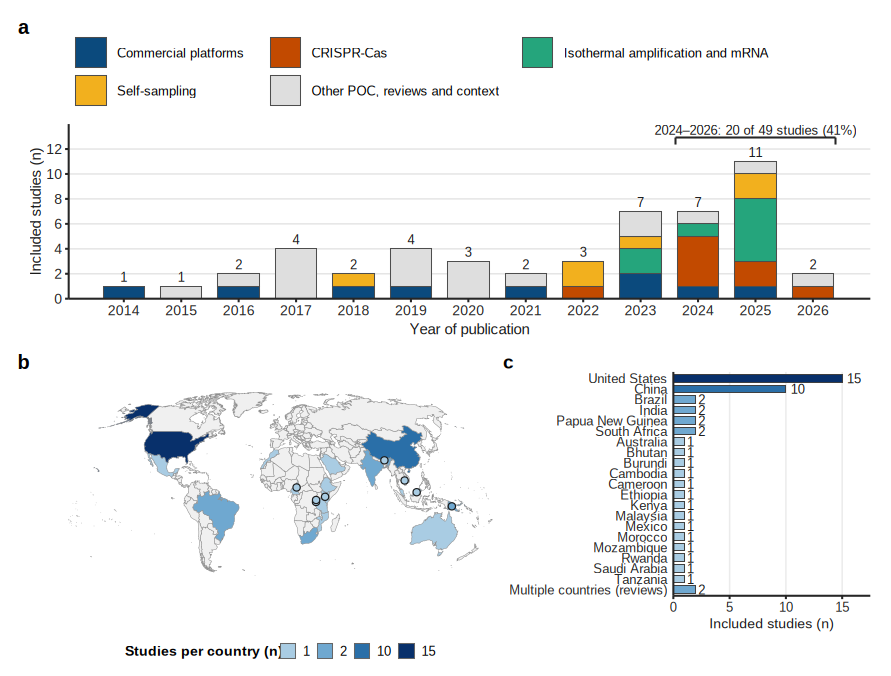

In [6]:
# ---- Figure 2: characteristics of the included studies = (a) years, (b) map, (c) per-country bars --------------
pbot <- (pm | pb) + plot_layout(widths = c(2.15, 1))
p23 <- (p2 / pbot) + plot_layout(heights = c(0.78, 1)) +
  plot_annotation(tag_levels = "a", theme = theme(plot.tag = element_text(face = "bold", size = 11, family = FONT)))
save_fig(p23, "Figure2_study_characteristics", 174, 132); show_fig(p23, 174, 132)


## 4. Figure 3 — Diagnostic accuracy in ROC space
Each study is one point (x = 1 − specificity, y = sensitivity); bars are reported 95% CIs; symbol shape marks approximate or lower-bound estimates; area ∝ sample size. Studies without a reported *n* are drawn at minimum size. It is a descriptive display, **not** a pooled (SROC) analysis.

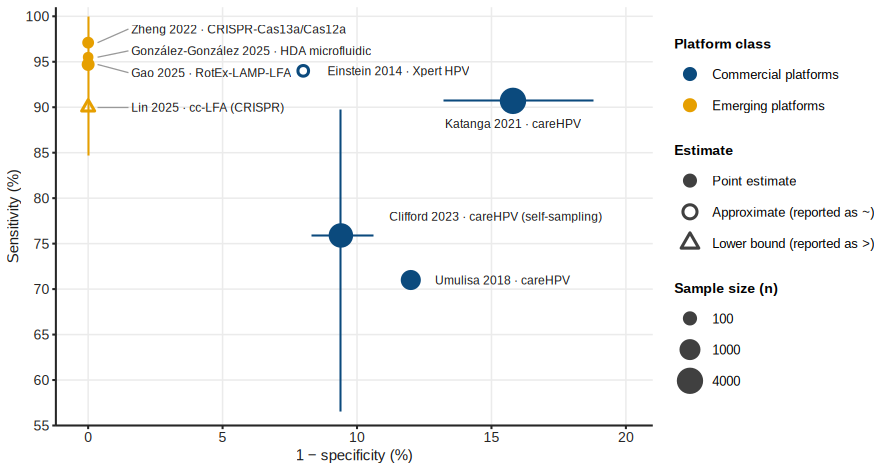

In [7]:
ap <- read_csv(file.path(DATA, "accuracy_points.csv"), show_col_types = FALSE) |>
  mutate(fpr = 100 - spec, fpr_lo = 100 - spec_hi, fpr_hi = 100 - spec_lo,
         est_type = case_when(sens_type == "lower" ~ "Lower bound (reported as >)",
                              sens_type == "approx" | spec_type == "approx" ~ "Approximate (reported as ~)",
                              TRUE ~ "Point estimate"),
         est_type = factor(est_type, levels = c("Point estimate", "Approximate (reported as ~)", "Lower bound (reported as >)")),
         class = factor(class, levels = c("Commercial", "Emerging"), labels = c("Commercial platforms", "Emerging platforms")),
         tag = paste0(study, " ", year, " · ", platform))

# Label positions are fixed by hand (deterministic, no random repel); leader lines join point and label
lab <- tribble(
  ~study,             ~lx,  ~ly,   ~hj,
  "Zheng",            1.6,  98.6,  0,
  "González-González",1.6,  96.2,  0,
  "Gao",              1.6,  93.8,  0,
  "Lin",              1.6,  90.0,  0,
  "Einstein",         8.9,  94.0,  0,
  "Katanga",          15.8, 88.2,  0.5,
  "Umulisa",          12.9, 71.0,  0,
  "Clifford",         11.2, 78.0,  0)
ap <- left_join(ap, lab, by = "study") |> mutate(n_plot = ifelse(is.na(n), 50, n))  # n not reported -> drawn at minimum size (50), see note
lead <- filter(ap, study %in% c("Zheng", "González-González", "Gao", "Lin"))

p3 <- ggplot(ap, aes(fpr, sens)) +
  geom_segment(data = lead, aes(x = fpr + 0.35, xend = lx - 0.1, y = sens, yend = ly), linewidth = 0.25, colour = "grey60") +
  geom_segment(data = filter(ap, !is.na(sens_lo)), aes(x = fpr, xend = fpr, y = sens_lo, yend = sens_hi, colour = class),
               linewidth = 0.4, show.legend = FALSE) +
  geom_segment(data = filter(ap, !is.na(spec_lo)), aes(x = fpr_lo, xend = fpr_hi, y = sens, yend = sens, colour = class),
               linewidth = 0.4, show.legend = FALSE) +
  geom_point(aes(colour = class, shape = est_type, size = n_plot), stroke = 0.9) +
  geom_text(aes(x = lx, y = ly, label = tag, hjust = hj), size = 2.3, family = FONT, colour = "grey10", vjust = 0.5) +
  scale_colour_manual(values = PAL_ROC, name = "Platform class") +
  scale_shape_manual(values = c(16, 1, 2), name = "Estimate") +
  scale_size_continuous(range = c(1.9, 6), trans = "sqrt", breaks = c(100, 1000, 4000), name = "Sample size (n)") +
  scale_x_continuous(limits = c(-1.2, 21), breaks = seq(0, 20, 5), expand = c(0, 0)) +
  scale_y_continuous(limits = c(55, 101), breaks = seq(55, 100, 5), expand = c(0, 0)) +
  labs(x = "1 − specificity (%)", y = "Sensitivity (%)") +
  guides(colour = guide_legend(order = 1, override.aes = list(shape = 16, size = 2.8)),
         shape  = guide_legend(order = 2, override.aes = list(colour = "grey25", size = 2.8)),
         size   = guide_legend(order = 3, override.aes = list(shape = 16, colour = "grey25"))) +
  theme_jms() + theme(panel.grid.major = element_line(colour = "grey92", linewidth = 0.3), legend.position = "right",
                      legend.box.just = "left", legend.spacing.y = unit(1.5, "mm"))
save_fig(p3, "Figure3_accuracy_ROC_space", 174, 92); show_fig(p3, 174, 92)


## 5. Figure 4 — Risk of bias (QUADAS-2)

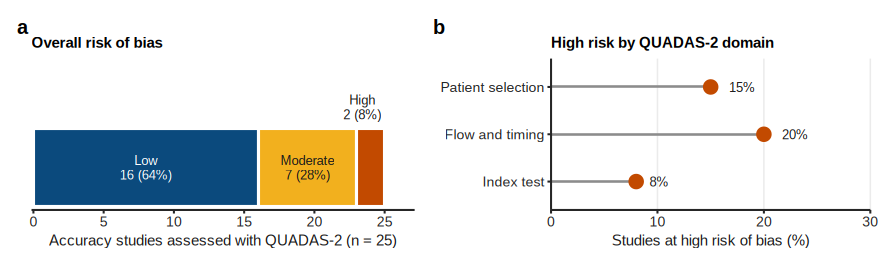

In [8]:
rb <- read_csv(file.path(DATA, "risk_of_bias.csv"), show_col_types = FALSE)
ov <- rb |> filter(panel == "overall") |>
  mutate(category = factor(category, levels = c("Low", "Moderate", "High"))) |> arrange(category) |>
  mutate(xmax = cumsum(value), xmin = xmax - value, mid = (xmin + xmax) / 2, pct = round(100 * value / sum(value)))
stopifnot(sum(ov$value) == 25)
cols_rb <- PAL_BIAS

pa <- ggplot(ov) +
  geom_rect(aes(xmin = xmin, xmax = xmax, ymin = 0, ymax = 1, fill = category), colour = "white", linewidth = 0.6) +
  geom_text(data = filter(ov, category != "High"), aes(mid, 0.5, label = sprintf("%s\n%d (%d%%)", category, value, pct)),
            size = 2.5, family = FONT, colour = c("white", "grey10"), lineheight = 0.95) +
  geom_text(data = filter(ov, category == "High"), aes(mid - 0.6, 1.12, label = sprintf("%s\n%d (%d%%)", category, value, pct)),
            size = 2.5, family = FONT, colour = "grey10", vjust = 0, lineheight = 0.95) +
  scale_fill_manual(values = cols_rb, guide = "none") +
  scale_x_continuous(breaks = seq(0, 25, 5), limits = c(0, 27), expand = c(0.005, 0)) +
  scale_y_continuous(limits = c(-0.05, 1.9), expand = c(0, 0)) +
  labs(x = "Accuracy studies assessed with QUADAS-2 (n = 25)", y = NULL, subtitle = "Overall risk of bias") +
  theme_jms() + theme(axis.line.y = element_blank(), axis.ticks.y = element_blank(), axis.text.y = element_blank(),
                      plot.subtitle = element_text(face = "bold", size = 8))

dm <- rb |> filter(panel == "domain") |> mutate(value = as.numeric(value), category = factor(category, levels = rev(category)))
pb <- ggplot(dm, aes(value, category)) +
  geom_segment(aes(x = 0, xend = value, yend = category), linewidth = 0.5, colour = "grey55") +
  geom_point(size = 3, colour = PAL_BIAS[["High"]]) +
  geom_text(aes(label = paste0(value, "%")), hjust = -0.7, size = 2.5, family = FONT, colour = "grey10") +
  scale_x_continuous(limits = c(0, 30), breaks = seq(0, 30, 10), expand = c(0, 0)) +
  labs(x = "Studies at high risk of bias (%)", y = NULL, subtitle = "High risk by QUADAS-2 domain") +
  theme_jms() + theme(panel.grid.major.x = element_line(colour = "grey92", linewidth = 0.3),
                      plot.subtitle = element_text(face = "bold", size = 8))

p4 <- (pa | pb) + plot_layout(widths = c(1.2, 1)) + plot_annotation(tag_levels = "a")
save_fig(p4, "Figure4_risk_of_bias", 174, 52); show_fig(p4, 174, 52)


## 6. Greyscale check
Colour printing is charged by the journal, so every figure must remain readable in greyscale. Adjacent classes of every palette must differ by at least 10 L* units; the notebook stops otherwise. Side-by-side proofs are saved in `figures/greyscale_proof/`.

                        figure                             class     hex L_star
     Fig 2a  technology groups              Commercial platforms #0B4A7D   30.5
     Fig 2a  technology groups                        CRISPR-Cas #C24A00   47.5
     Fig 2a  technology groups Isothermal amplification and mRNA #25A57C   60.6
     Fig 2a  technology groups                     Self-sampling #F2B01E   76.1
     Fig 2a  technology groups    Other POC, reviews and context #DEDEDE   88.5
 Fig 2b,c  studies per country                                15 #08306B   20.9
 Fig 2b,c  studies per country                                10 #2A6FA8   45.2
 Fig 2b,c  studies per country                                 2 #6FA8D0   66.5
 Fig 2b,c  studies per country                                 1 #A9CCE3   80.3
 Fig 2b,c  studies per country                              none #F0F0F0   94.8
         Fig 3  platform class              Commercial platforms #0B4A7D   30.5
         Fig 3  platform class          


Minimum adjacent dL* per figure (rule: >= 10):


    Fig 2a  technology groups Fig 2b,c  studies per country 
                         12.4                          13.8 
        Fig 3  platform class  Fig 4a  overall risk of bias 
                         40.1                          16.9 


Linking to ImageMagick 6.9.12.98
Enabled features: fontconfig, freetype, fftw, heic, lcms, pango, raw, webp, x11
Disabled features: cairo, ghostscript, rsvg



Using 2 threads



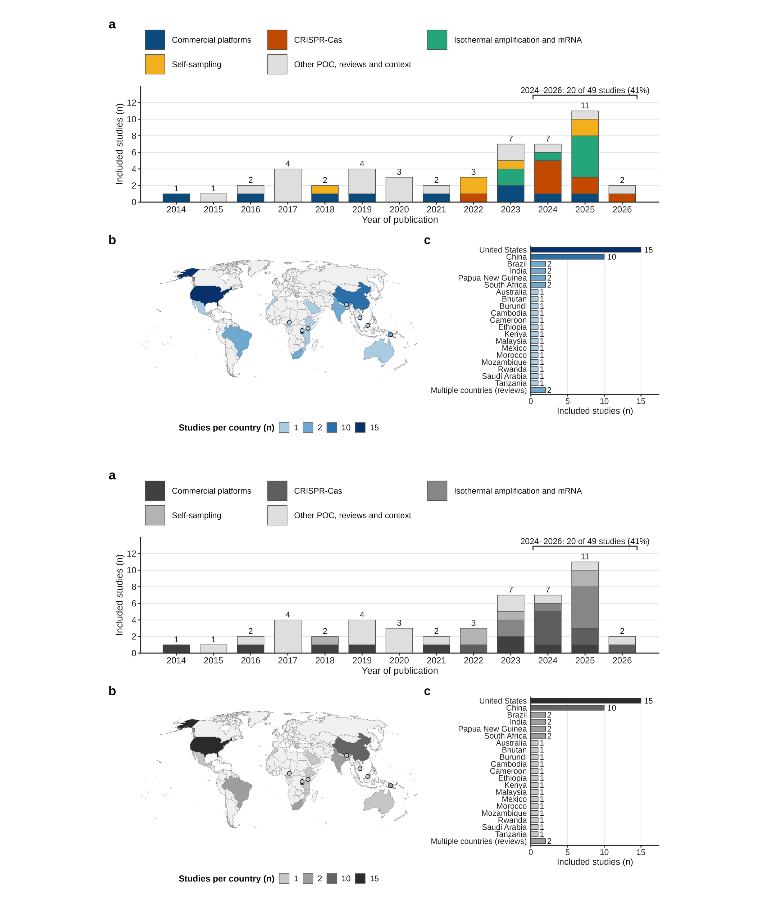

In [9]:
# ---- Greyscale / colour-vision check of every palette used in the figures ---------------------------------------
library(colorspace)
lstar <- function(hex) { x <- hex2RGB(hex); coords(as(x, "LAB"))[, "L"] }       # CIE L* (0 black .. 100 white), D65
sets <- list(
  "Fig 2a  technology groups" = PAL_GROUP,
  "Fig 2b,c  studies per country" = c(none = PAL_NONE, PAL_CLASS),
  "Fig 3  platform class" = PAL_ROC,
  "Fig 4a  overall risk of bias" = PAL_BIAS)
chk <- do.call(rbind, lapply(names(sets), function(k) {
  v <- sets[[k]]; L <- lstar(unname(v)); o <- order(L)
  data.frame(figure = k, class = names(v)[o], hex = unname(v)[o], L_star = round(L[o], 1), dL_to_next = c(round(diff(L[o]), 1), NA))
}))
print(chk, row.names = FALSE)
min_dL <- tapply(chk$dL_to_next, chk$figure, min, na.rm = TRUE)
cat("\nMinimum adjacent dL* per figure (rule: >= 10):\n"); print(round(min_dL, 1))
stopifnot(all(min_dL >= 10))                                   # the notebook fails if a palette collapses in greyscale

# ---- Greyscale proofs (600-dpi PNGs -> 8-bit luminance) side by side with the colour versions ----------------
library(magick)
dir.create(file.path(FIG, "greyscale_proof"), showWarnings = FALSE)
for (f in c("Figure2_study_characteristics", "Figure3_accuracy_ROC_space", "Figure4_risk_of_bias")) {
  im <- image_read(file.path(FIG, paste0(f, ".png"))); im <- image_resize(im, "1600x")
  g  <- image_convert(im, colorspace = "Gray")
  image_write(image_append(image_border(c(im, g), "white", "20x20"), stack = TRUE), file.path(FIG, "greyscale_proof", paste0(f, "_colour_vs_grey.png")))
}
options(repr.plot.width = 7, repr.plot.height = 8.2, repr.plot.res = 110)
pr <- png::readPNG(file.path(FIG, "greyscale_proof", "Figure2_study_characteristics_colour_vs_grey.png"))
grid::grid.newpage(); grid::grid.raster(pr)


## 7. Consistency checks against the manuscript text

In [10]:
# ---- Cross-checks between the numbers in the figures and the manuscript text -----
t3 <- read_csv(file.path(DATA, "table3_studies.csv"), col_types = cols(.default = "c"), show_col_types = FALSE)
cat("Studies in Table 3:", nrow(t3), "(manuscript: 49)\n")
cat("Published 2024-2026:", sum(as.integer(t3$year) >= 2024), "\n")
cat("careHPV studies:", sum(t3$poc_platform == "careHPV"), "| Xpert HPV:", sum(grepl("Xpert", t3$poc_platform)), "\n")
cat("Self-sampling = Yes:", sum(grepl("^Yes", t3$self_sampling)), "(manuscript text says 12)\n")
cat("\nStudies per country in Table 3 (the manuscript text lists different counts: see report):\n")
print(sort(table(t3$country), decreasing = TRUE))
cat("\nSample sizes reported in Table 3 add up to:", sum(as.numeric(gsub(",", "", t3$n[grepl("^[0-9,]+$", t3$n)]))),
    "(manuscript Final considerations claims >10,000)\n")


Studies in Table 3: 49 (manuscript: 49)


Published 2024-2026: 20 


careHPV studies: 6 | Xpert HPV: 2 


Self-sampling = Yes: 11 (manuscript text says 12)



Studies per country in Table 3 (the manuscript text lists different counts: see report):



         USA        China       Brazil        India     Multiple          PNG 
          15           10            2            2            2            2 
South Africa    Australia       Bhutan      Burundi     Cambodia     Cameroon 
           2            1            1            1            1            1 
    Ethiopia        Kenya     Malaysia       Mexico      Morocco   Mozambique 
           1            1            1            1            1            1 
      Rwanda Saudi Arabia     Tanzania 
           1            1            1 



Sample sizes reported in Table 3 add up to: 7967 (manuscript Final considerations claims >10,000)


In [11]:
# ---- Figures quoted in the Results/Discussion (geography) ---------------------------------
cnr <- t3 |> count(country, name = "n") |> left_join(reg, by = "country")
reg_n <- cnr |> group_by(region) |> summarise(studies = sum(n), countries = sum(country != "Multiple"), .groups = "drop") |> arrange(desc(studies))
print(as.data.frame(reg_n))
top2 <- sum(cnr$n[cnr$country %in% c("USA", "China")])
cat(sprintf("USA + China: %d of 49 studies (%.1f%%)\n", top2, 100 * top2 / 49))
for (rg in c("Sub-Saharan Africa", "Latin America")) { k <- reg_n$studies[reg_n$region == rg]; cat(sprintf("%s: %d studies (%.1f%%)\n", rg, k, 100 * k / 49)) }
cat("Self-sampling = Yes (incl. 'Yes (urine)'):", sum(grepl("^Yes", t3$self_sampling)), "\n")


                        region studies countries
1                North America      15         1
2                    East Asia      10         1
3           Sub-Saharan Africa       9         8
4   Southeast Asia and Oceania       5         4
5                Latin America       3         2
6                   South Asia       3         2
7 Middle East and North Africa       2         2
8           Multiple countries       2         0


USA + China: 25 of 49 studies (51.0%)


Sub-Saharan Africa: 9 studies (18.4%)
Latin America: 3 studies (6.1%)


Self-sampling = Yes (incl. 'Yes (urine)'): 11 


## 8. Session information

In [12]:
sessionInfo()


R version 4.3.3 (2024-02-29)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 24.04.5 LTS

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/blas/libblas.so.3.12.0 
LAPACK: /usr/lib/x86_64-linux-gnu/lapack/liblapack.so.3.12.0

locale:
 [1] LC_CTYPE=C.UTF-8    LC_NUMERIC=C        LC_TIME=C          
 [4] LC_COLLATE=C        LC_MONETARY=C       LC_MESSAGES=C      
 [7] LC_PAPER=C          LC_NAME=C           LC_ADDRESS=C       
[10] LC_TELEPHONE=C      LC_MEASUREMENT=C    LC_IDENTIFICATION=C

time zone: America/Manaus
tzcode source: system (glibc)

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
[1] magick_2.8.2     colorspace_2.1-0 sf_1.0-15        patchwork_1.2.0 
[5] stringr_1.5.1    readr_2.1.5      tidyr_1.3.1      dplyr_1.1.4     
[9] ggplot2_3.4.4   

loaded via a namespace (and not attached):
 [1] utf8_1.2.4         generics_0.1.3     class_7.3-22       KernSmooth_2.23-22
 [5] stringi